## Representative Acoustic States (RAS)

clone `https://github.com/dbetchkal/ras.git`, `https://github.com/dbetchkal/NPS-ActiveSpace.git`, `https://github.com/lilythchu/STSW.git`

`python -m pip install -e ".[dev,stsw,plot]"`

In [43]:
import numpy as np
import os
import sys

# ----------------------------------------------------------------------
# LOCAL REPOSITORIESgit 
# ----------------------------------------------------------------------
repo_dir = r"C:\Users\DBetchkal\CODE\GITHUB"
# ----------------------------------------------------------------------
sys.path.append(os.path.join(repo_dir, "iyore"))
sys.path.append(os.path.join(repo_dir, "NPS-ActiveSpace"))
sys.path.append(os.path.join(repo_dir, "STSW"))
sys.path.append(os.path.join(repo_dir, "ras"))
import iyore
from nps_active_space.utils.models import Nvspl, Srcid
from methods import stswd
from ras import RAS, RASConfig, PreprocessingConfig, STSWConfig

##### The API starts with a user-prepared spectrogram `S`.
We've data and the means to parse it in `nps_active_space`:

In [ ]:
import glob

nv_path = r"C:\Users\DBetchkal\CODE\GITHUB\NPS-ActiveSpace\example_data\nvspl_archive\2024 GLBALSTL Lower South Tidal Inlet\01 DATA\NVSPL"
nv_files = glob.glob(nv_path + os.sep + "NVSPL*.txt")

nv = Nvspl(nv_files) # let's attempt to analyze 25 day samples... but we'll take anything we can get up to that
                             # TODO: ensure a consecutive, 25-day sample is available

if not np.isnan(nv["WindSpeed"]).all():
    nv = nv.loc[nv["WindSpeed"] <= 5.0, :] # standard procedure to remove pseudonoise artifacts
S = nv.loc[:, "12.5":"20000"].copy()

#### Analyze `S`

In [ ]:
model = RAS(RASConfig())
result = model.analyze(S)   # S is a DataFrame with DatetimeIndex

# PRIMARY RESULTS:
S_E = result.S_E            # Ambient-relative spectral contrast
M = result.M                # Hypersphere of spectral directions
X_N = result.X_N            # Representative Acoustic States matrix
S_Pi = result.S_Pi          # Spectrogram, RAS-partitioned
G = result.G_MST            # Minimum Spanning Tree graph
G_diameter = result.diam    # Diameter of the MST graph      
medoid = result.x_star      # Occupancy-weighted spherical medoid, x*

----

#### A more complex example: derive `S` from audio, analyze

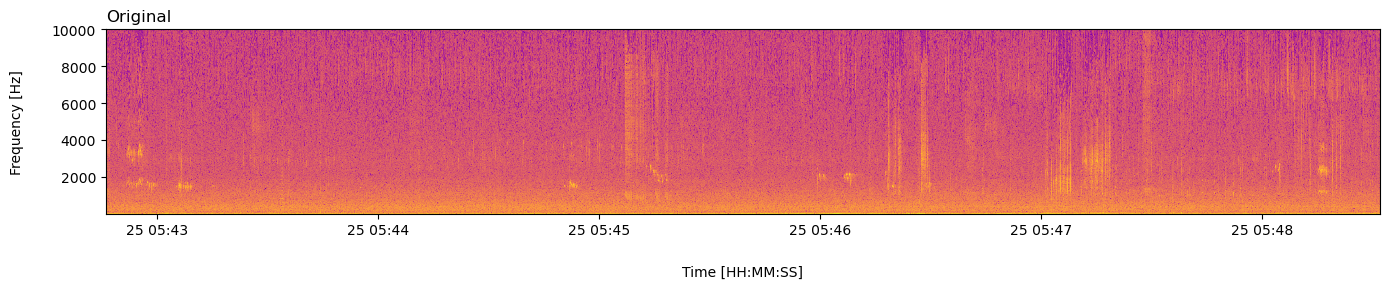

In [55]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path
import re
from scipy import signal
from scipy.io import wavfile

# Matches: _YYYYMMDD_HHMMSS followed by whitespace or end of filename.
_RECORDING_TIME_RE = re.compile(r"_(?P<date>\d{8})_(?P<time>\d{6})(?=\s|$)")


def wav_spectrogram_dataframe(
    audio_path,
    scale="linear",
    n_bands=128,
    nperseg=512,
    noverlap=None,
    min_frequency=10.0,
    max_frequency=None,
    timezone=None,
    output="db",
):
    """
    Create a spectrogram DataFrame with absolute timestamps.

    Parameters
    ----------
    audio_path : str or pathlib.Path
        Path to a WAV file whose name contains "_YYYYMMDD_HHMMSS".

    scale : {"linear", "log", "mel"}, default "linear"
        Frequency-axis spacing.

        "linear"
            Return the native, linearly spaced FFT bins produced by the STFT.
            In this mode, n_bands is ignored.

        "log"
            Aggregate the native FFT bins into logarithmically spaced bands.

        "mel"
            Aggregate the native FFT bins into Mel-spaced bands.

    n_bands : int, default 128
        Number of frequency bands for "log" or "mel".

    nperseg : int, default 512
        Number of samples in each STFT segment.

    noverlap : int or None, default None
        Number of overlapping samples between adjacent STFT segments.
        If None, scipy.signal.stft uses nperseg // 2.

    min_frequency : float, default 0.0
        Lowest frequency to include, in Hz.

        For logarithmic spacing, a value less than or equal to zero is
        automatically replaced with the first positive FFT frequency.

    max_frequency : float or None, default None
        Highest frequency to include, in Hz. If None, use the Nyquist
        frequency.

    timezone : str or None, default None
        Optional timezone for the returned DatetimeIndex, such as
        "America/Anchorage". The filename itself is assumed to represent
        local clock time in that timezone.

    output : {"db", "power", "magnitude"}, default "db"
        Values returned in the DataFrame.

        "db"
            Power in decibels: 10 * log10(power).

        "power"
            Squared STFT magnitude.

        "magnitude"
            STFT magnitude.

    Returns
    -------
    pandas.DataFrame
        Rows are absolute timestamps and columns are band-center
        frequencies in Hz.

    Raises
    ------
    ValueError
        If the filename does not contain "_YYYYMMDD_HHMMSS", or if an
        unsupported scale or output is requested.
    """
    audio_path = Path(audio_path)

    # ------------------------------------------------------------------
    # 1. Extract the recording start time from the filename.
    # ------------------------------------------------------------------
    match = _RECORDING_TIME_RE.search(audio_path.stem)

    if match is None:
        raise ValueError(
            "Could not find a recording timestamp in the filename. "
            "Expected '_YYYYMMDD_HHMMSS', for example "
            "'GAARNARV_20140615_004935 description.wav'."
        )

    recording_start = pd.to_datetime(
        match.group("date") + match.group("time"),
        format="%Y%m%d%H%M%S",
    )

    if timezone is not None:
        recording_start = recording_start.tz_localize(timezone)

    # ------------------------------------------------------------------
    # 2. Read the audio and convert multichannel audio to mono.
    # ------------------------------------------------------------------
    sample_rate, samples = wavfile.read(audio_path)

    samples = np.asarray(samples)

    if samples.ndim == 2:
        # scipy.io.wavfile returns shape (samples, channels).
        samples = samples.astype(np.float64).mean(axis=1)
    elif samples.ndim != 1:
        raise ValueError(
            f"Expected mono or multichannel audio, got shape {samples.shape}."
        )

    # Convert integer PCM to floating point approximately in [-1, 1].
    if np.issubdtype(samples.dtype, np.integer):
        dtype_info = np.iinfo(samples.dtype)

        if dtype_info.min < 0:
            normalizer = max(abs(dtype_info.min), dtype_info.max)
            samples = samples.astype(np.float64) / normalizer
        else:
            # Center unsigned PCM, such as 8-bit WAV data.
            midpoint = (dtype_info.max + 1) / 2
            samples = (samples.astype(np.float64) - midpoint) / midpoint
    else:
        samples = samples.astype(np.float64)

    # ------------------------------------------------------------------
    # 3. Compute the STFT.
    #
    # boundary=None and padded=False avoid adding synthetic samples before
    # or after the recording. The returned times identify window centers.
    # ------------------------------------------------------------------
    frequencies, elapsed_seconds, zxx = signal.stft(
        samples,
        fs=sample_rate,
        nperseg=nperseg,
        noverlap=noverlap,
        boundary=None,
        padded=False,
    )

    magnitude = np.abs(zxx)
    power = magnitude**2

    nyquist = sample_rate / 2
    maximum = nyquist if max_frequency is None else min(
        float(max_frequency), nyquist
    )

    if maximum <= min_frequency:
        raise ValueError(
            "max_frequency must be greater than min_frequency."
        )

    scale = scale.lower()

    # ------------------------------------------------------------------
    # 4. Construct the requested frequency bands.
    # ------------------------------------------------------------------
    if scale == "linear":
        frequency_mask = (
            (frequencies >= min_frequency)
            & (frequencies <= maximum)
        )

        band_centers = frequencies[frequency_mask]
        band_power = power[frequency_mask, :]
        band_magnitude = magnitude[frequency_mask, :]

    elif scale in {"log", "mel"}:
        if not isinstance(n_bands, int) or n_bands < 1:
            raise ValueError("n_bands must be a positive integer.")

        positive_frequencies = frequencies[frequencies > 0]

        if positive_frequencies.size == 0:
            raise ValueError("No positive FFT frequencies were produced.")

        if scale == "log":
            lower = max(
                float(min_frequency),
                float(positive_frequencies[0]),
            )

            if maximum <= lower:
                raise ValueError(
                    "The logarithmic frequency range contains no usable bins."
                )

            band_edges = np.geomspace(lower, maximum, n_bands + 1)
            band_centers = np.sqrt(band_edges[:-1] * band_edges[1:])

        else:
            lower = max(float(min_frequency), 0.0)

            def hz_to_mel(hz):
                return 2595.0 * np.log10(1.0 + np.asarray(hz) / 700.0)

            def mel_to_hz(mel):
                return 700.0 * (
                    10.0 ** (np.asarray(mel) / 2595.0) - 1.0
                )

            mel_edges = np.linspace(
                hz_to_mel(lower),
                hz_to_mel(maximum),
                n_bands + 1,
            )

            band_edges = mel_to_hz(mel_edges)
            band_centers = mel_to_hz(
                (mel_edges[:-1] + mel_edges[1:]) / 2
            )

        band_power = np.full(
            (n_bands, power.shape[1]),
            np.nan,
            dtype=np.float64,
        )
        band_magnitude = np.full_like(band_power, np.nan)

        for band_number, (lower_edge, upper_edge) in enumerate(
            zip(band_edges[:-1], band_edges[1:])
        ):
            # Include the upper endpoint in the final band.
            if band_number == n_bands - 1:
                mask = (
                    (frequencies >= lower_edge)
                    & (frequencies <= upper_edge)
                )
            else:
                mask = (
                    (frequencies >= lower_edge)
                    & (frequencies < upper_edge)
                )

            if np.any(mask):
                # Averaging power is preferable to averaging decibel values.
                band_power[band_number, :] = np.mean(
                    power[mask, :],
                    axis=0,
                )

                band_magnitude[band_number, :] = np.mean(
                    magnitude[mask, :],
                    axis=0,
                )

    else:
        raise ValueError(
            "scale must be 'linear', 'log', or 'mel'."
        )

    # ------------------------------------------------------------------
    # 5. Select the output units.
    # ------------------------------------------------------------------
    output = output.lower()

    if output == "power":
        spectrogram = band_power
    elif output == "magnitude":
        spectrogram = band_magnitude
    elif output == "db":
        # Prevent log10(0), while retaining the available dynamic range.
        spectrogram = 10.0 * np.log10(
            np.maximum(band_power, np.finfo(float).tiny)
        )
    else:
        raise ValueError(
            "output must be 'db', 'power', or 'magnitude'."
        )

    # ------------------------------------------------------------------
    # 6. Turn elapsed STFT time into absolute timestamp values.
    # ------------------------------------------------------------------
    timestamps = pd.DatetimeIndex(
        recording_start
        + pd.to_timedelta(elapsed_seconds, unit="s"),
        name="timestamp",
    )

    result = pd.DataFrame(
        spectrogram.T,
        index=timestamps,
        columns=pd.Index(
            band_centers,
            name="frequency_hz",
        ),
    )

    return result

# audio_path = r"C:\Users\DBetchkal\OneDrive - DOI\Desktop\AUDIO CUTS\GAARNARV_20140615_004935 Swainson's Thrush calls and song, entire bout.wav"
# audio_path = r"T:\ResMgmt\Sound\Denali Sound Library\Audio\Birds\DENAKICH_20120527_045810 chorus with GCSP focus, but also HETH calls, FOSP and WISP.wav"
audio_path = r"T:\ResMgmt\Sound\Media\AUDIO CLIPS\0 Canonical Type-1 Clips\BIRD ID\DENATRLA_20240725_054246 long sequence of varied Gray Jay calls.wav"

# Native FFT bins, linearly spaced
S = wav_spectrogram_dataframe(audio_path,
                              scale="linear",
                              nperseg=2048,
                              output="db")

S = S.loc[:, S.columns[S.columns < 10000]] # in this example there is little information in the signal >10 kHz

fig, ax = plt.subplots(1, 1, figsize=(14, 3), sharex=True)
ax.pcolormesh(S.index, S.columns, S.T.values, cmap='plasma', shading="nearest")
ax.set_title("Original", loc="left")
plt.ylabel('Frequency [Hz]', labelpad=20)
plt.xlabel('Time [HH:MM:SS]', labelpad=20)
plt.tight_layout()
plt.show()

In [56]:
config = RASConfig(preprocessing=PreprocessingConfig(epsilon_t_seconds=20, # the timescale of audio-derived spectrograms is different than NVSPL
                                                     frequency_footprint_bands=S.columns.size,
                                                     f_lower_hz=S.columns.min(),
                                                     f_upper_hz=S.columns.max()),
                   stsw=STSWConfig(batch_size=256))

model = RAS(config)
result = model.analyze(S)   # S is a DataFrame with DatetimeIndex

# PRIMARY RESULTS:
S_E = result.S_E            # Ambient-relative spectral contrast
M = result.M                # Hypersphere of spectral directions
X_N = result.X_N            # Representative Acoustic States matrix
S_Pi = result.S_Pi          # Spectrogram, RAS-partitioned
G = result.G_MST            # Minimum Spanning Tree graph
G_diameter = result.diam    # Diameter of the MST graph      
medoid = result.x_star      # Occupancy-weighted spherical medoid, x*

2026-11-13 15:34:04,591 - INFO - Hypersphere M has been estimated.
2026-11-13 15:34:04,594 - INFO - Sampled hyperspherical points.
2026-11-13 15:34:29,744 - INFO - Representative acoustic states X_N have been learned.
2026-11-13 15:34:29,798 - INFO - A representative state has been assigned to each frame in M
2026-11-13 15:34:29,806 - INFO - The medoid and it's eccentricity have been calculated.
2026-11-13 15:34:31,097 - INFO - The Minimum Spanning Tree Graph has been created and relevant structure analyzed.


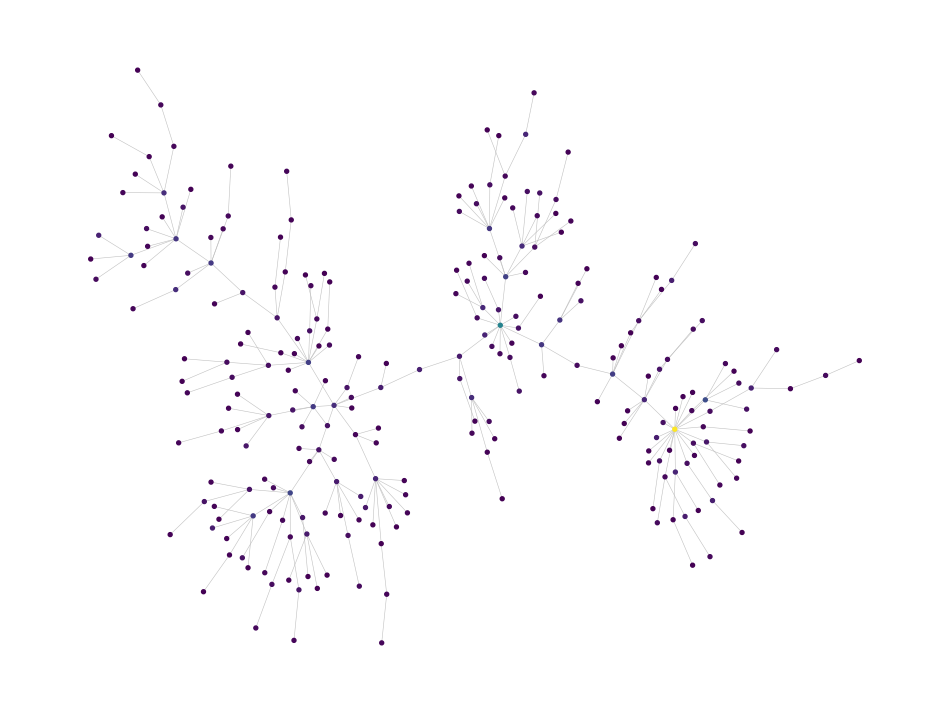

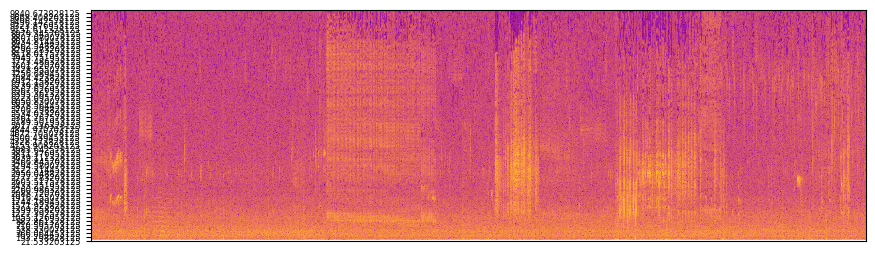

In [57]:
from ras.plotting import event_plotter, plot_mst

G = result.G_MST 
fig,ax = plt.subplots(1,1, figsize=(12,9))
plot_mst(G, ax=ax, node_color=result.mu_E[list(G.nodes)], edge_color="silver")
plt.show()

# the maximum-exposure state
S_state_sel = S_Pi.loc[S_Pi["state"] == np.argmax(result.mu_E), :].iloc[:, :-2]

fig,ax = plt.subplots(1,1, figsize=(10,3))
event_plotter(S_state_sel, ax, vmin=S_state_sel.min().min(), vmax=S_state_sel.max().max())
ax.tick_params(labelsize=6)
ax.set_xticks([])
plt.show()